## VAE Demo on the EMNIST Dataset

In [66]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.manifold import TSNE
from tqdm import tqdm

from utils.dataset import load_data
from utils.layers import VAE
from utils.losses import vae_loss
from utils.optim import Adam
from utils.tensor import Tensor


Load and format the EMNIST dataset (fix the orientation and binarize, details in utils.dataset)

In [67]:
X_train, y_train, X_test, y_test = load_data()

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (112800, 784)
Test set shape: (18800, 784)


Define the model and optimizer configs. Further details on the architecture can be found in utils.layers.

In [ ]:
config = {"input_size": 784, "hidden_size": 128, "latent_size": 64}
model = VAE(**config)
optimizer = Adam(model.parameters())

Train the model!

Epoch 8/8: 100%|██████████| 1763/1763 [00:05<00:00, 345.61it/s, loss=173.68]


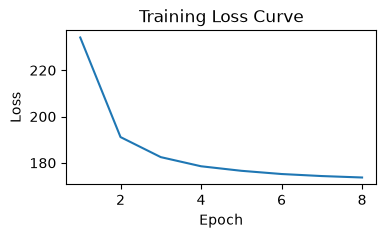

In [69]:
epochs = 8
losses = []
for epoch in range(epochs):
    total_loss = 0
    batch_size = 64
    perm = np.random.permutation(len(X_train))
    pbar = tqdm(range(0, len(X_train), batch_size), desc=f"Epoch {epoch + 1}/{epochs}")
    for start in pbar:
        idx = perm[start : start + batch_size]
        x = Tensor(X_train[idx])
        optimizer.zero_grad()
        x_hat, mean, logvar = model(x)
        loss = vae_loss(x, x_hat, mean, logvar, beta=3)
        loss.backward()
        optimizer.step()
        total_loss += loss.data
        seen = start + len(idx)
        pbar.set_postfix(loss=f"{total_loss / seen:.2f}")
    losses.append({"epoch": epoch + 1, "loss": total_loss / seen})
plt.figure(figsize=(4, 2))
plt.title("Training Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.plot([l["epoch"] for l in losses], [l["loss"] for l in losses], label="Loss")
plt.savefig("figures/training_loss.png", bbox_inches="tight")

We can check a few examples from the test set to see how well images are being reproduced.

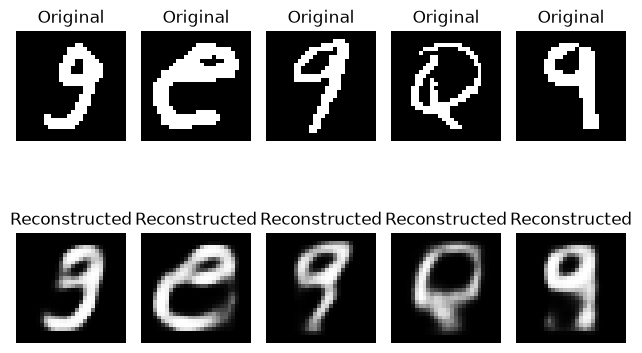

In [70]:
for i in range(5):
    original = X_test[i]
    x = Tensor(original.reshape(1, -1))
    x_hat, _, _ = model(x)
    reconstructed = x_hat.data.reshape(28, 28)
    plt.subplot(2, 5, i + 1)
    plt.imshow(original.reshape(28, 28), cmap='gray')
    plt.axis('off')
    plt.title('Original')
    plt.subplot(2, 5, i + 6)
    plt.imshow(reconstructed, cmap='gray')
    plt.axis('off')
    plt.title('Reconstructed')
plt.tight_layout()
plt.savefig("figures/reconstruction.png", bbox_inches="tight")

We can also visualize the latent space of the trained model to confirm that labels are roughly clustered.

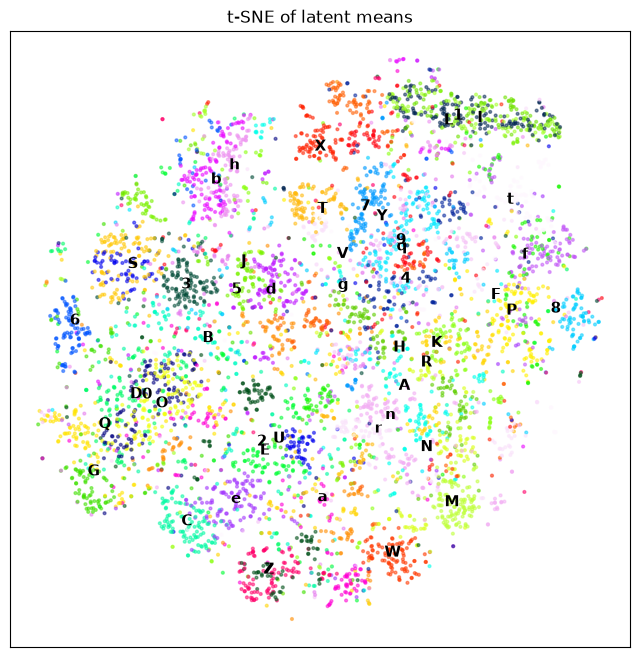

In [71]:
chars = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabdefghnqrt"
groups = np.array(["digit"] * 10 + ["upper"] * 26 + ["lower"] * 11)

# Encode all images in the test set 
rng = np.random.default_rng(0)
sub = rng.choice(len(X_test), 6000, replace=False)
mu, _ = model.encoder.forward(Tensor(X_test[sub]))
latents, labels = mu.data, y_test[sub]

# Embed with t-SNE
emb = TSNE(n_components=2, perplexity=40, init="pca", random_state=0).fit_transform(latents)

# Points coloured by class
plt.figure(figsize=(8, 8))
plt.scatter(emb[:, 0], emb[:, 1], c=labels, cmap="gist_ncar", s=4, alpha=0.5)
for k in range(len(chars)):
    cx, cy = np.median(emb[labels == k], axis=0)
    plt.text(cx, cy, chars[k], fontsize=11, weight="bold", ha="center", va="center")
plt.title("t-SNE of latent means")
plt.xticks([]); plt.yticks([])
plt.savefig("figures/tsne.png", bbox_inches="tight")

Finally, we can generate some new images by sampling in the latent space. First, randomly sampling a few points.

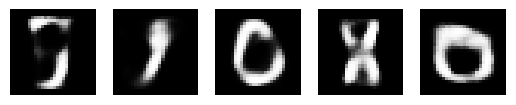

In [72]:
for i in range(5):
    z = Tensor(np.random.normal(size=(1, config["latent_size"])))
    x_hat = model.decoder.forward(z)
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_hat.data.reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.savefig("figures/samples.png", bbox_inches="tight")

And we can also morph samples from the test set into each other by interpolating between them.

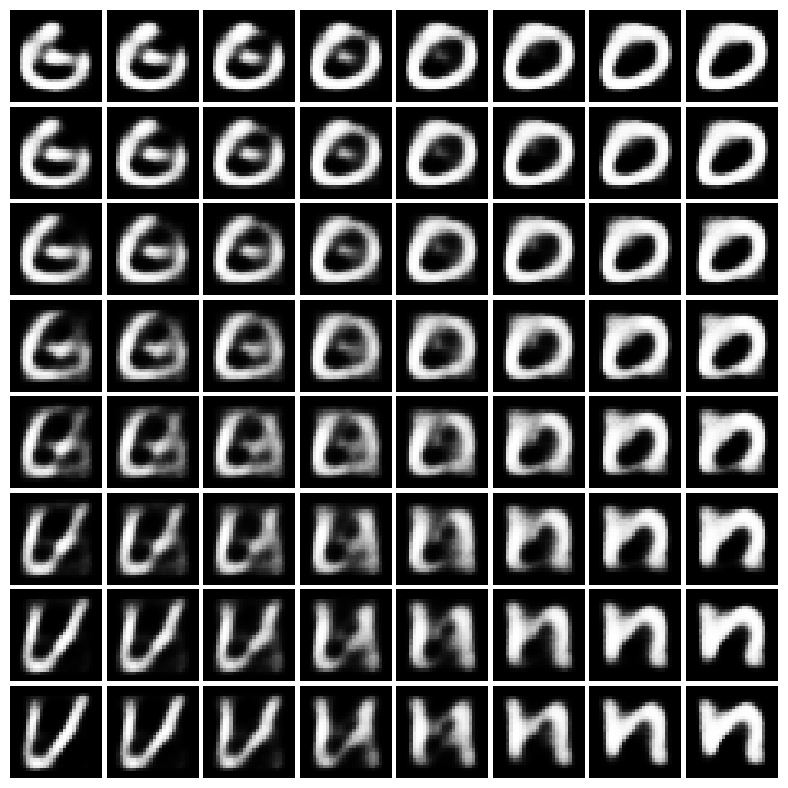

In [73]:
# Pick 4 distinct random indices from the test set to visualize
indices = np.random.choice(len(X_test), 4, replace=False)
z1, z2, z3, z4 = (model.encoder.forward(Tensor(X_test[i].reshape(1, -1)))[0].data for i in indices)

plt.figure(figsize=(8, 8))
for i in range(8):
    for j in range(8):
        alpha = i / 7
        beta = j / 7
        z_interpolated = (1 - alpha) * ((1 - beta) * z1 + beta * z2) + alpha * ((1 - beta) * z3 + beta * z4)
        interpolated_image = model.decoder.forward(Tensor(z_interpolated)).data.reshape(28, 28)
        plt.subplot(8, 8, i * 8 + j + 1)
        plt.imshow(interpolated_image, cmap="gray")
        plt.axis("off")
    
plt.subplots_adjust(left=0.02, right=0.98, top=0.98, bottom=0.02, wspace=0.05, hspace=0.05)
plt.savefig("figures/interpolation.png", bbox_inches="tight")